In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from keras.models import Sequential
from keras.layers import Input, Dense, Conv1D, MaxPooling1D, TimeDistributed, Flatten
from keras.layers import LSTM, Dropout, Bidirectional
from keras.layers import LeakyReLU
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import StandardScaler
import yfinance as yf

In [2]:
# Get data from Yahoo finance
df = yf.download('GLD', start='2020-01-01')
df.head()

[*********************100%%**********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2020-01-02,143.860001,144.210007,143.399994,143.949997,143.949997,7733800
2020-01-03,145.750000,146.320007,145.399994,145.860001,145.860001,12272800
2020-01-06,148.440002,148.479996,146.949997,147.389999,147.389999,14403300
2020-01-07,147.570007,148.139999,147.429993,147.970001,147.970001,7978500
2020-01-08,148.490005,148.610001,146.139999,146.860001,146.860001,22248500


In [3]:
# Info
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 940 entries, 2020-01-02 to 2023-09-26
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       940 non-null    float64
 1   High       940 non-null    float64
 2   Low        940 non-null    float64
 3   Close      940 non-null    float64
 4   Adj Close  940 non-null    float64
 5   Volume     940 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 51.4 KB


In [4]:
# Log Close
df['Log_Close'] = np.log(df['Close'])

In [5]:
# Compute the first difference of Log_Close(Log Returns)
df['Diff_Log_Close'] = df['Log_Close'].diff()

In [6]:
# Split data into train and test
Ntest = 10
train = df.iloc[:-Ntest]
test = df.iloc[-Ntest:]

In [7]:
# Standardize the Time Series values
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train[['Diff_Log_Close']])
test_scaled = scaler.fit_transform(test[['Diff_Log_Close']])

In [8]:
# Boolean series to index df rows
train_idx = df.index <= train.index[-1]
test_idx = df.index > train.index[-1]

In [9]:
# Put the Scaled 'Diff_Log_Close' back to dataframe use the column name 'Scaled_Log_Ret'
# We use flatten function because Scikit-Learn returns 2D arrays
df.loc[train_idx, 'Scaled_Log_Ret'] = train_scaled.flatten()
df.loc[test_idx, 'Scaled_Log_Ret'] = test_scaled.flatten()

In [10]:
# Make Supervised Dataset
series = df['Scaled_Log_Ret'].dropna().to_numpy()
T = 120
X = []
Y = []

for t in range(len(series) - T):
  x = series[t: t+T]
  X.append(x)
  y = series[t+T]
  Y.append(y)

X = np.array(X).reshape(-1, 1, T, 1) # we make 4D array for TimeDistributed wrapper in our model
Y = np.array(Y)

print('X Shape: ', X.shape, 'Y Shape: ', Y.shape)

X Shape:  (819, 1, 120, 1) Y Shape:  (819,)


In [11]:
# Split our supervised dataset into train and test
Xtrain, Xtest = X[:-Ntest], X[-Ntest:]
Ytrain, Ytest = Y[:-Ntest], Y[-Ntest:]

In [12]:
# Create our CNN-LSTM Model

# TimeDistributed: It allows you to apply the same layer independently to each time step in your data,
# preserving the temporal relationships between different time steps.

# Flatten: Flatten layer is used to make the multidimensional input one-dimensional,
# commonly used in the transition from the convolution layer to the full connected layer

# Bidirectional: Bidirectional LSTM or BiLSTM is a term used for a sequence model which contains two LSTM layers,
# one for processing input in the forward direction and the other for processing in the backward direction.

model = Sequential()

# CNN layers
model.add(Input(shape=(None, T, 1)))
model.add(TimeDistributed(Conv1D(64, kernel_size=3)))
model.add(LeakyReLU(alpha=0.05))
model.add(TimeDistributed(MaxPooling1D(2)))
model.add(TimeDistributed(Conv1D(128, kernel_size=3)))
model.add(LeakyReLU(alpha=0.05))
model.add(TimeDistributed(MaxPooling1D(2)))
model.add(TimeDistributed(Conv1D(64, kernel_size=3)))
model.add(LeakyReLU(alpha=0.05))
model.add(TimeDistributed(MaxPooling1D(2)))
model.add(TimeDistributed(Flatten()))

# LSTM layers
model.add(Bidirectional(LSTM(100, return_sequences=True)))
model.add(LeakyReLU(alpha=0.05))
model.add(Dropout(0.5))
model.add(Bidirectional(LSTM(100, return_sequences=False)))
model.add(LeakyReLU(alpha=0.05))
model.add(Dropout(0.5))

# Final layers
model.add(Dense(1, activation='linear'))

In [13]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 time_distributed (TimeDist  (None, None, 118, 64)     256       
 ributed)                                                        
                                                                 
 leaky_re_lu (LeakyReLU)     (None, None, 118, 64)     0         
                                                                 
 time_distributed_1 (TimeDi  (None, None, 59, 64)      0         
 stributed)                                                      
                                                                 
 time_distributed_2 (TimeDi  (None, None, 57, 128)     24704     
 stributed)                                                      
                                                                 
 leaky_re_lu_1 (LeakyReLU)   (None, None, 57, 128)     0         
                                                        

In [14]:
# Call Compile Function
model.compile(optimizer='adam', loss='mse', metrics=['mse', 'mae'])

In [15]:
# Call Fit Function
r = model.fit(Xtrain, Ytrain, epochs=100, validation_data=(Xtest, Ytest))

Epoch 1/100
26/26 [==============================] - 25s 94ms/step - loss: 0.8797 - mse: 0.8797 - mae: 0.6925 - val_loss: 1.0005 - val_mse: 1.0005 - val_mae: 0.8387
Epoch 2/100
26/26 [==============================] - 0s 11ms/step - loss: 0.8820 - mse: 0.8820 - mae: 0.6932 - val_loss: 0.9994 - val_mse: 0.9994 - val_mae: 0.8384
Epoch 3/100
26/26 [==============================] - 0s 12ms/step - loss: 0.8824 - mse: 0.8824 - mae: 0.6925 - val_loss: 1.0005 - val_mse: 1.0005 - val_mae: 0.8386
Epoch 4/100
26/26 [==============================] - 0s 13ms/step - loss: 0.8786 - mse: 0.8786 - mae: 0.6901 - val_loss: 0.9985 - val_mse: 0.9985 - val_mae: 0.8380
Epoch 5/100
26/26 [==============================] - 0s 11ms/step - loss: 0.8748 - mse: 0.8748 - mae: 0.6882 - val_loss: 1.0088 - val_mse: 1.0088 - val_mae: 0.8401
Epoch 6/100
26/26 [==============================] - 0s 11ms/step - loss: 0.8666 - mse: 0.8666 - mae: 0.6886 - val_loss: 1.0023 - val_mse: 1.0023 - val_mae: 0.8390
Epoch 7/100
26/

In [16]:
# History's Keys
r.history.keys()

dict_keys(['loss', 'mse', 'mae', 'val_loss', 'val_mse', 'val_mae'])

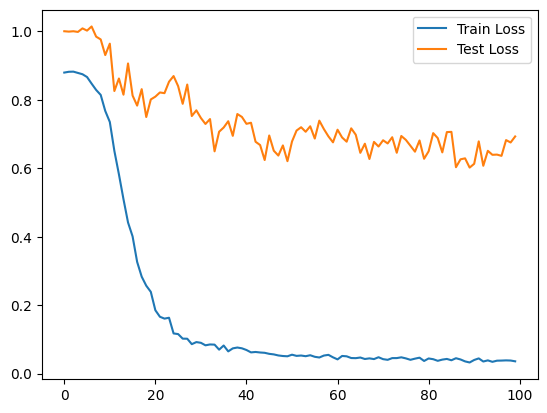

In [17]:
# Plot
plt.plot(r.history['loss'], label='Train Loss')
plt.plot(r.history['val_loss'], label='Test Loss')
plt.legend();

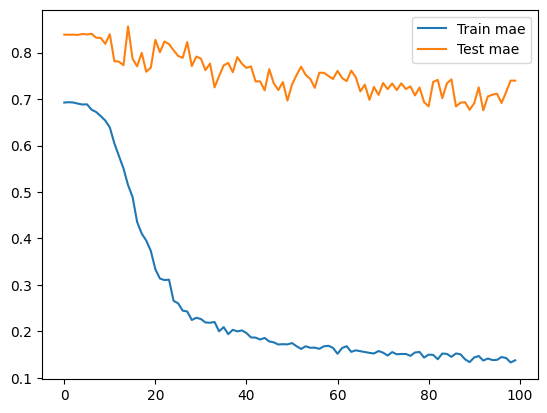

In [18]:
# Plot
plt.plot(r.history['mae'], label='Train mae')
plt.plot(r.history['val_mae'], label='Test mae')
plt.legend();

In [19]:
# First T values are not predictable
train_idx[:T+1] = False

In [20]:
# Make Prediction
Ptrain = model.predict(Xtrain)
Ptest = model.predict(Xtest)
Ptrain.shape

1/1 [==============================] - 0s 21ms/step


(809, 1)

In [21]:
# Invert the Scaling
Ptrain = scaler.inverse_transform(Ptrain).flatten()
Ptest = scaler.inverse_transform(Ptest).flatten()

In [22]:
# Store Diff Predictions
df.loc[train_idx, 'Diff_Train_Pred'] = Ptrain
df.loc[test_idx, 'Diff_Test_Pred'] = Ptest

In [23]:
# Plot
px.line(df, x=df.index, y=['Diff_Log_Close', 'Diff_Train_Pred', 'Diff_Test_Pred'])

In [24]:
# Shifted Log Close values will use to Compute Un-Differenced Predictions
df['Shifted_Log_Close'] = df['Log_Close'].shift(1)
prev = df['Shifted_Log_Close']

In [25]:
# 1 step forecast
df.loc[train_idx, '1_Step_pred_Train'] = prev[train_idx] + Ptrain
df.loc[test_idx, '1_Step_pred_Test'] = prev[test_idx] + Ptest

In [26]:
# Plot 1-Step Forecast
px.line(df, x=df.index, y=['Log_Close', '1_Step_pred_Train', '1_Step_pred_Test'])

In [27]:
# Multi-Step Forecast
multistep_predictions = []

In [28]:
# First test input
last_x = Xtrain[-1]

In [29]:
# multistep_predictions list
while len(multistep_predictions) < Ntest:
  p = model.predict(last_x.reshape(-1, 1, T, 1))
  # Update the predictions list
  multistep_predictions.append(p)
  # Make the new input
  last_x = np.roll(last_x, -1) # Roll function spins our list 1 unit.
  last_x[-1] = p # P value will replace with last value of our list.

multistep_predictions

1/1 [==============================] - 0s 19ms/step


[array([[-0.6319915]], dtype=float32),
 array([[-0.01300353]], dtype=float32),
 array([[-0.06299745]], dtype=float32),
 array([[-0.06406039]], dtype=float32),
 array([[-0.06415076]], dtype=float32),
 array([[-0.06415842]], dtype=float32),
 array([[-0.06415907]], dtype=float32),
 array([[-0.06415911]], dtype=float32),
 array([[-0.0641591]], dtype=float32),
 array([[-0.0641591]], dtype=float32)]

In [30]:
# Invert the Scaling
multistep_predictions = np.array(multistep_predictions)
multistep_predictions = scaler.inverse_transform(multistep_predictions.reshape(-1,1)).flatten() # reshape is required for scikit-learn

In [31]:
# Last-Known train value
last_train = train.iloc[-1]['Log_Close']

In [32]:
# Save multi-step forecast to dataframe
df.loc[test_idx, 'Multi_Step'] = last_train + np.cumsum(multistep_predictions)

In [33]:
# Plot 1-Step and Molti-Step Forecast
px.line(df, x=df.index, y=['Log_Close', '1_Step_pred_Test', 'Multi_Step'])

In [34]:
# Make Multi-Output Supervised Dataset
Tx = T # Tx represent the number of time steps in the input
Ty = Ntest # Ty represent the number of time steps in the output
X = []
Y = []
for t in range(len(series) - Tx - Ty + 1):
  x = series[t: t+Tx]
  X.append(x)
  y = series[t+Tx: t+Tx+Ty]
  Y.append(y)

X = np.array(X).reshape(-1, 1, Tx, 1)
Y = np.array(Y).reshape(-1, Ty)

print('X shape: ', X.shape, 'Y shape: ', Y.shape)

X shape:  (810, 1, 120, 1) Y shape:  (810, 10)


In [35]:
# Split data into train and test
Xtrain_m, Ytrain_m = X[:-1], Y[:-1]
Xtest_m, Ytest_m = X[-1:], Y[-1:]

In [36]:
# Create our CNN-LSTM Model

model = Sequential()

# CNN layers
model.add(Input(shape=(None, Tx, 1)))
model.add(TimeDistributed(Conv1D(64, kernel_size=3)))
model.add(LeakyReLU(alpha=0.05))
model.add(TimeDistributed(MaxPooling1D(2)))
model.add(TimeDistributed(Conv1D(128, kernel_size=3)))
model.add(LeakyReLU(alpha=0.05))
model.add(TimeDistributed(MaxPooling1D(2)))
model.add(TimeDistributed(Conv1D(64, kernel_size=3)))
model.add(LeakyReLU(alpha=0.05))
model.add(TimeDistributed(MaxPooling1D(2)))
model.add(TimeDistributed(Flatten()))

# LSTM layers
model.add(Bidirectional(LSTM(100, return_sequences=True)))
model.add(LeakyReLU(alpha=0.05))
model.add(Dropout(0.5))
model.add(Bidirectional(LSTM(100, return_sequences=False)))
model.add(LeakyReLU(alpha=0.05))
model.add(Dropout(0.5))

# Final layers
model.add(Dense(Ty, activation='linear'))

In [37]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 time_distributed_7 (TimeDi  (None, None, 118, 64)     256       
 stributed)                                                      
                                                                 
 leaky_re_lu_5 (LeakyReLU)   (None, None, 118, 64)     0         
                                                                 
 time_distributed_8 (TimeDi  (None, None, 59, 64)      0         
 stributed)                                                      
                                                                 
 time_distributed_9 (TimeDi  (None, None, 57, 128)     24704     
 stributed)                                                      
                                                                 
 leaky_re_lu_6 (LeakyReLU)   (None, None, 57, 128)     0         
                                                      

In [38]:
# Call Compile Function
model.compile(optimizer='adam', loss='mse', metrics=['mse', 'mae'])

In [39]:
# Call Fit Function
r = model.fit(Xtrain, Ytrain, epochs=100, validation_data=(Xtest, Ytest))

Epoch 1/100
26/26 [==============================] - 11s 72ms/step - loss: 0.8819 - mse: 0.8819 - mae: 0.6918 - val_loss: 0.9999 - val_mse: 0.9999 - val_mae: 0.8387
Epoch 2/100
26/26 [==============================] - 0s 12ms/step - loss: 0.8809 - mse: 0.8809 - mae: 0.6914 - val_loss: 0.9998 - val_mse: 0.9998 - val_mae: 0.8388
Epoch 3/100
26/26 [==============================] - 0s 11ms/step - loss: 0.8811 - mse: 0.8811 - mae: 0.6914 - val_loss: 1.0001 - val_mse: 1.0001 - val_mae: 0.8389
Epoch 4/100
26/26 [==============================] - 0s 13ms/step - loss: 0.8807 - mse: 0.8807 - mae: 0.6914 - val_loss: 0.9998 - val_mse: 0.9998 - val_mae: 0.8387
Epoch 5/100
26/26 [==============================] - 0s 16ms/step - loss: 0.8779 - mse: 0.8779 - mae: 0.6890 - val_loss: 1.0000 - val_mse: 1.0000 - val_mae: 0.8381
Epoch 6/100
26/26 [==============================] - 0s 16ms/step - loss: 0.8715 - mse: 0.8715 - mae: 0.6868 - val_loss: 0.9933 - val_mse: 0.9933 - val_mae: 0.8367
Epoch 7/100
26/

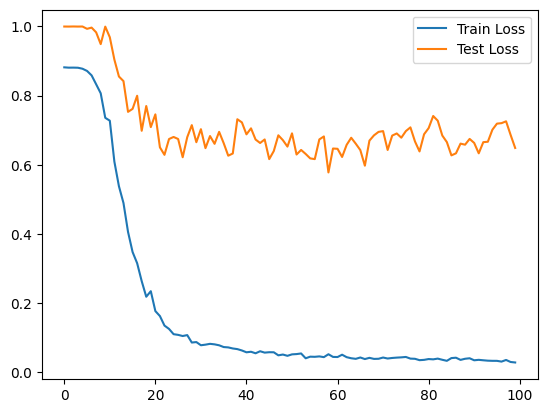

In [40]:
# Plot
plt.plot(r.history['loss'], label='Train Loss')
plt.plot(r.history['val_loss'], label='Test Loss')
plt.legend();

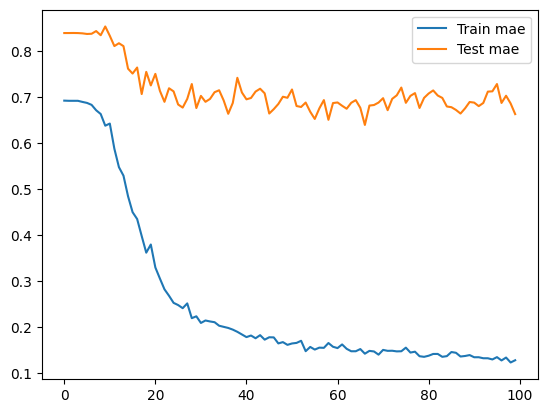

In [41]:
# Plot
plt.plot(r.history['mae'], label='Train mae')
plt.plot(r.history['val_mae'], label='Test mae')
plt.legend();

In [42]:
# Make Prediction
# Note that we do not flatten() the prediction
Ptrain = model.predict(Xtrain_m)
Ptest = model.predict(Xtest_m)

1/1 [==============================] - 0s 22ms/step


In [43]:
# Shape
Ptrain.shape, Ptest.shape

((809, 10), (1, 10))

In [44]:
# Index our prediction
Ptrain = Ptrain[:, 0]
Ptest = Ptest[0]

In [45]:
# Unscale
Ptest = scaler.inverse_transform(Ptest.reshape(-1,1)).flatten()

In [46]:
# Save Multi-Step Forecast to DataFrame
df.loc[test_idx, 'Multi_OutPut'] = last_train + np.cumsum(Ptest)

In [47]:
# Plot all Forecasts
px.line(df, x=df.index, y=['Log_Close', '1_Step_pred_Test', 'Multi_Step', 'Multi_OutPut'])

In [48]:
# MAPE
test_log_Close = df.iloc[-Ntest:]['Log_Close']
mape_1 = mean_absolute_percentage_error(test_log_Close, df.loc[test_idx, '1_Step_pred_Test'])
print('1Step MAPE: ', mape_1)
mape_2 = mean_absolute_percentage_error(test_log_Close, df.loc[test_idx, 'Multi_Step'])
print('Multi-Step MAPE: ', mape_2)
mape_3 = mean_absolute_percentage_error(test_log_Close, df.loc[test_idx, 'Multi_OutPut'])
print('Multi-OutPut MAPE: ', mape_3)

1Step MAPE:  0.0006908382916411981
Multi-Step MAPE:  0.0022215224012446027
Multi-OutPut MAPE:  0.0011029069863111348


In [49]:
# R2 Score
test_log_Close = df.iloc[-Ntest:]['Log_Close']
R2_1 = r2_score(test_log_Close, df.loc[test_idx, '1_Step_pred_Test'])
print('1Step R2: ', R2_1)
R2_2 = r2_score(test_log_Close, df.loc[test_idx, 'Multi_Step'])
print('Multi-Step R2: ', R2_2)
R2_3 = r2_score(test_log_Close, df.loc[test_idx, 'Multi_OutPut'])
print('Multi-OutPut R2: ', R2_3)

1Step R2:  0.4950414436556564
Multi-Step R2:  -4.259126985072581
Multi-OutPut R2:  -0.38712546681816007
